In [ ]:
import momi		## momi2 analysis
import logging		## create log file

logging.basicConfig(level=logging.INFO,
                    filename="new_muts_momi_log.txt")

In [2]:
%%sh
python -m momi.extract_sfs new_final_sfs.gz 100 /scratch/fm2371/momi_new/counts_new/*.snpAlleleCounts.gz

In [3]:
## Load the sfs data
sfs = momi.Sfs.load("new_final_sfs.gz")

In [4]:
%%bash
gunzip -c new_final_sfs.gz | head

{
	"sampled_pops": ["US"],
	"folded": true,
	"length": 2252044789.0,
	"configs": [
		[[186, 2]],
		[[185, 3]],
		[[184, 4]],
		[[183, 5]],
		[[182, 6]],


In [5]:
#load the sfs data,avg number of hets per ind per pop (assuming Hardy-Weinberg)
#print("Avg pairwise heterozygosity", sfs.avg_pairwise_hets)
print("populations", sfs.populations)
print("percent missing data per population", sfs.p_missing)

populations ('US',)
percent missing data per population [0.02991884]


In [6]:
# Common parameters
Ne = 2.2e7  # Effective population size, calculated based on He
mu = 2.8e-9  # Mutation rate
gen_time =1 #Generation Time

# Time of introduction into Korea and the US, reported by people, the actual invasive time could be ealier
t_korea = 2022 - 2004  # 18 years ago
t_us = 2022 - 2014  # 8 years ago


In [113]:
# Model 1: Constant population size

# Initialize a demographic model with a constant population size
model_constant = momi.DemographicModel(N_e=Ne, gen_time=gen_time,muts_per_gen=mu)

# Add a size parameter for the contemporary population
model_constant.add_size_param(name="n_contemp", lower=1e1, upper=1e8)

# Add the SLF population as a leaf in the demographic model
model_constant.add_leaf("US")

model_constant.add_time_param("t_inital", lower=0, upper=100) 

# Set the data for the model (replace 'sfs' with your actual SFS data)
model_constant.set_data(sfs)

# Optimize the model to fit the data
result = model_constant.optimize(method="L-BFGS-B",options={"maxiter": 500}) #Truncated Newton Conjugate-gradient not get converged.This is very accurate but can be slow for large models; for large models, method="L-BFGS-B" is a good choice.

# Display the results
print(result)

            fun: 1796.693253099363
       hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>
            jac: array([0., 0.])
  kl_divergence: 1796.693253099363
 log_likelihood: -538950785.7185186
        message: b'CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL'
           nfev: 1
            nit: 0
           njev: 1
     parameters: ParamsDict({'n_contemp': 7908971.1354903625, 't_inital': 66.41102486116002})
         status: 0
        success: True
              x: array([15.88350826,  0.68166519])


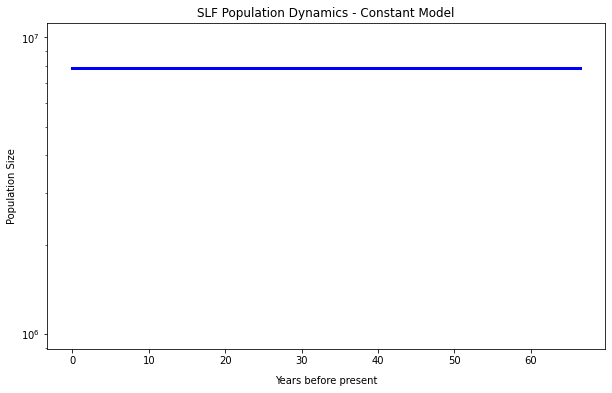

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Optimized parameter values from the constant model
n_contemp = 7908971.1354903625
t_initial = 66.41102486116002

# Generate time points for plotting
time_points = np.linspace(0, t_initial, 1000)

# Calculate population size at each time point
population_size = np.full_like(time_points, n_contemp)

# Plotting for the constant model
plt.figure(figsize=(10, 6))
plt.plot(time_points, population_size, color='blue', linewidth=3)
plt.xlabel('Years before present', labelpad=10)
plt.ylabel('Population Size')
plt.title('SLF Population Dynamics - Constant Model')
plt.grid(False)
plt.yscale('log')
plt.savefig("SLF_Constant_Model_Plot.png", format='png')
plt.show()

In [114]:
# Model 2: Expansion population size

model_expansion = momi.DemographicModel(N_e=Ne, gen_time=gen_time,muts_per_gen=mu)#add mutation rate makes very recent time period converged

# Add size parameters
model_expansion.add_size_param("n_init", lower=1e1, upper=1e4)  # Initial population size before expansion, the range has to be lower than current size
model_expansion.add_size_param("n_contemp", lower=1e4, upper=1e8)  # Contemporary population size

# Add time parameters
model_expansion.add_time_param("t_initial", lower=0, upper=100)  # Time of expansion, even could happen before SLF were there

# Add the leaf population (SLF in the US)
model_expansion.add_leaf("US", N="n_init")

# Add the demographic events
model_expansion.set_size("US", t="t_initial", N="n_contemp")

# Set the data
model_expansion.set_data(sfs)

# Print parameters
#print(model_expansion.get_params())
# Run the optimization
result_model_expansion=model_expansion.optimize(method="TNC")
print(result_model_expansion)


            fun: 0.7765045295758033
            jac: array([3.94560153e-05, 6.20471412e-01, 1.37118862e-08])
  kl_divergence: 0.7765045295758033
 log_likelihood: -1317964.1996729425
        message: 'Local minimum reached (|pg| ~= 0)'
           nfev: 32
            nit: 13
     parameters: ParamsDict({'n_init': 10.000000000000002, 'n_contemp': 10000.00000000001, 't_initial': 0.1774388543541894})
         status: 0
        success: True
              x: array([ 2.30258509,  9.21034037, -6.33252343])


In [115]:
# Model 3: Decline population size

model_decline = momi.DemographicModel(N_e=Ne, gen_time=gen_time, muts_per_gen=mu)

# Add size parameters
model_decline.add_size_param("n_init", lower=1e4, upper=1e8)  # Initial population size before decline
model_decline.add_size_param("n_contemp", lower=1e1, upper=1e4)  # Contemporary population size after decline, the same with inital size for Expansion model.

# Add time parameters
model_decline.add_time_param("t_initial", lower=0, upper=100)  # keep time of decline the same as in expansion model

# Add the leaf population (SLF in the US)
model_decline.add_leaf("US", N="n_init")

# Add the demographic events
#model_decline.set_size("US", t="t_init", N="n_init")
model_decline.set_size("US", t="t_initial", N="n_contemp")

# Set the data
model_decline.set_data(sfs)

# Print parameters (Optional)
print(model_decline.get_params())

# Run the optimization
result_model_decline = model_decline.optimize(method="TNC", options={"maxiter": 500})

# Print the result
print(result_model_decline)


ParamsDict({'n_init': 15873754.571860114, 'n_contemp': 5668.009283561372, 't_initial': 58.02568233928568})
            fun: 0.4679806211029051
            jac: array([2.08397511e-10, 6.13176710e-09, 1.72392567e-06])
  kl_divergence: 0.4679806211029051
 log_likelihood: -1225603.2483368618
        message: 'Converged (|f_n-f_(n-1)| ~= 0)'
           nfev: 28
            nit: 11
     parameters: ParamsDict({'n_init': 19194206.536149774, 'n_contemp': 2319.9630149611294, 't_initial': 0.0004899486454302199})
         status: 1
        success: True
              x: array([ 16.77011905,   7.74930652, -12.22637526])


In [118]:
# Model 4: Decline then Expansion Model(arrived the US 10 years ago when size decline and recently expand)

model_decline_expand = momi.DemographicModel(N_e=Ne, gen_time=gen_time, muts_per_gen=mu)

# Add size parameters
model_decline_expand.add_size_param("n_init", lower=1e4, upper=1e8)
model_decline_expand.add_size_param("n_us_decline", lower=1e1, upper=1e4)
model_decline_expand.add_size_param("n_us_expand", lower=1e4, upper=1e8)

# Add time parameters
model_decline_expand.add_time_param("t_initial", lower=12, upper=100)
# Time of decline: assuming the decline might have started up to 5 years ago and lasted until the expansion phase
model_decline_expand.add_time_param("t_us_decline", lower=6, upper=11)
# Time of expansion: assuming the expansion started sometime in the last 10 years
model_decline_expand.add_time_param("t_us_expand", lower=0, upper=5)

# Add the leaf population (SLF in the US)
model_decline_expand.add_leaf("US", N="n_init")

# Add the demographic events
# First decline
#model_decline_expand.set_size("US", t="t_initial", N="n_init")
model_decline_expand.set_size("US", t="t_us_decline", N="n_us_decline")
# Then expansion
model_decline_expand.set_size("US", t="t_us_expand", N="n_us_expand")

# Set the data
model_decline_expand.set_data(sfs)

# Print parameters
print(model_decline_expand.get_params())

# Run the optimization
result_model_decline_expand = model_decline_expand.optimize(method="TNC", options={"maxiter": 500})

# Print the result
print(result_model_decline_expand)


ParamsDict({'n_init': 98262553.56485932, 'n_us_decline': 2555.0362282148985, 'n_us_expand': 9540334.050488358, 't_initial': 75.56962793576072, 't_us_decline': 7.350189457985172, 't_us_expand': 0.9192705923136802})
            fun: 0.48219874903490745
            jac: array([4.35826433e-12, 7.30480477e-06, 5.37817353e-03, 0.00000000e+00,
       4.14090617e-09, 2.59520357e-10])
  kl_divergence: 0.48219874903490745
 log_likelihood: -1229859.6439870978
        message: 'Converged (|f_n-f_(n-1)| ~= 0)'
           nfev: 34
            nit: 8
     parameters: ParamsDict({'n_init': 605470.462180968, 'n_us_decline': 2536.528197155776, 'n_us_expand': 10000.00000000001, 't_initial': 75.56962793576072, 't_us_decline': 6.000001987639386, 't_us_expand': 2.412783957699757e-07})
         status: 1
        success: True
              x: array([ 13.31376106,   7.83855157,   9.21034037,   0.95630869,
       -14.73800038, -16.84675227])


In [119]:
# Model 5: Complex Migration and Size Change Model(Assume SLF expericed size decline when they reach to Korea, which is around 20 years ago, and then expand in Korea, and then they were introduced to the US around 10 years ago, which leads size decline in their size and recently expand again)
# As we don’t have data from Korea and China, basically we are testing a model that has size changed four times, which is decline and then expasion and then decline again and fianlly expansion.

model_complex_us = momi.DemographicModel(N_e=Ne, gen_time=gen_time, muts_per_gen=mu)

# Add size parameters
# Add size parameters
model_complex_us.add_size_param("n_initial", lower=1e4, upper=1e8)   # Initial population size
model_complex_us.add_size_param("n_korea_decline1", lower=1e1, upper=1e4)  # Size after decline in Korea
model_complex_us.add_size_param("n_korea_expand1", lower=1e4, upper=1e8)   # Size after expansion in Korea
model_complex_us.add_size_param("n_us_decline2", lower=1e1, upper=1e4)  # Size after decline in the US
model_complex_us.add_size_param("n_us_expand2", lower=1e4, upper=1e8)   # Size after expansion in the US

# Add time parameters for each size change
# First decline in Korea, they were reported in Korean since 2004, but it could be ealier
model_complex_us.add_time_param("t_initial", lower=23, upper=100) #  before in Korea
model_complex_us.add_time_param("t_korea_decline1", lower=17, upper=22) #  2000 to 2006
# First expansion in Korea, must be after the first decline
model_complex_us.add_time_param("t_korea_expand1", lower=12, upper=16) #  2006 to 2010
# Second decline in the US
model_complex_us.add_time_param("t_us_decline2", lower=6, upper=11) # upper limit in the US: could be ealier than 2014, (2011 to 2017)
# Recent expansion in the US
model_complex_us.add_time_param("t_us_expand2", lower=0, upper=5) #0 means the year of 2022, (2017 to 2022)

# Add the leaf population (SLF in the US)
model_complex_us.add_leaf("US", N="n_initial")

# Add the demographic events
#model_complex_us.set_size("US", t="t_initial", N="n_initial")
model_complex_us.set_size("US", t="t_korea_decline1", N="n_korea_decline1")
model_complex_us.set_size("US", t="t_korea_expand1", N="n_korea_expand1")
model_complex_us.set_size("US", t="t_us_decline2", N="n_us_decline2")
model_complex_us.set_size("US", t="t_us_expand2", N="n_us_expand2")

# Set the data
model_complex_us.set_data(sfs)

# Run the optimization
result_model_complex_us = model_complex_us.optimize(method="TNC", options={"maxiter": 500})

# Print the result
print(result_model_complex_us)


            fun: 0.45449585092505757
            jac: array([ 1.58650882e-12,  2.62094940e-11, -2.39564311e-08, -5.53164596e-10,
        1.72821720e-03,  0.00000000e+00, -2.11532155e-08,  1.65867718e-08,
        2.18113930e-11,  7.29355001e-10])
  kl_divergence: 0.45449585092505757
 log_likelihood: -1221566.3935973407
        message: 'Converged (|f_n-f_(n-1)| ~= 0)'
           nfev: 81
            nit: 18
     parameters: ParamsDict({'n_initial': 4609542.905089804, 'n_korea_decline1': 2594.983302081868, 'n_korea_expand1': 100000000.00000018, 'n_us_decline2': 307.75347207479257, 'n_us_expand2': 10000.00000000001, 't_initial': 34.029693804484324, 't_korea_decline1': 21.999798828336836, 't_korea_expand1': 12.000024748703398, 't_us_decline2': 6.000000009485941, 't_us_expand2': 1.4234980233590303e-06})
         status: 1
        success: True
              x: array([ 15.34363926,   7.86133536,  18.42068074,   5.72929905,
         9.21034037,  -1.78861366,  10.12074965, -11.99302563,
      

In [8]:
# Model 6: Complex Migration and Size Change Model through Shanghai
#In this model, we assume the SLF in shanghai gone through population size change beacuse urbanization or small population went to shanghai urban areas, which has population size decline. 
# Then some of them were introduced to Korea and had population size change again.
#Finally, some of them were introduced to the US and had population size change again.

model_complex_global = momi.DemographicModel(N_e=Ne, gen_time=gen_time)
                                             
                                             #, muts_per_gen=mu)

# Add size parameters
model_complex_global.add_size_param("n_initial", lower=1e4, upper=1e8)   # Initial population size
model_complex_global.add_size_param("n_shanghai_decline1", lower=1e1, upper=1e4)   # Size after decline in Shanghai
model_complex_global.add_size_param("n_shanghai_expand1", lower=1e4, upper=1e8)   # Size after expansion in Shanghai
model_complex_global.add_size_param("n_korea_decline2", lower=1e1, upper=1e4)  # Size after decline in Korea
model_complex_global.add_size_param("n_korea_expand2", lower=1e4, upper=1e8)   # Size after expansion in Korea
model_complex_global.add_size_param("n_us_decline3", lower=1e1, upper=1e4)  # Size after decline in the US
model_complex_global.add_size_param("n_us_expand3", lower=1e4, upper=1e8)   # Size after expansion in the US

# Add time parameters for each event
model_complex_global.add_time_param("t_initial", lower=61, upper=100)  # Time of initial population
model_complex_global.add_time_param("t_shanghai_decline1", lower=36, upper=60)  # Time of first decline in Shanghai
model_complex_global.add_time_param("t_shanghai_expand1", lower=23, upper=35)   # Time of first expansion in Shanghai
model_complex_global.add_time_param("t_korea_decline2", lower=17, upper=22)  # Time of second decline in Korea
model_complex_global.add_time_param("t_korea_expand2", lower=12, upper=16)   # Time of second expansion in Korea
model_complex_global.add_time_param("t_us_decline3", lower=6, upper=11)  # Time of third decline in the US
model_complex_global.add_time_param("t_us_expand3", lower=0, upper=5)   # Time of third expansion in the US

# Add the leaf population (SLF in the US)
model_complex_global.add_leaf("US", N="n_initial")

# Add the demographic events
#model_complex_global.set_size("US", t="t_initial", N="n_initial")
model_complex_global.set_size("US", t="t_us_expand3", N="n_us_expand3")
model_complex_global.set_size("US", t="t_us_decline3", N="n_us_decline3")
model_complex_global.set_size("US", t="t_korea_expand2", N="n_korea_expand2")
model_complex_global.set_size("US", t="t_korea_decline2", N="n_korea_decline2")
model_complex_global.set_size("US", t="t_shanghai_expand1", N="n_shanghai_expand1")
model_complex_global.set_size("US", t="t_shanghai_decline1", N="n_shanghai_decline1")

# Set the data
model_complex_global.set_data(sfs)

# Run the optimization
result_model_complex_global = model_complex_global.optimize(method="TNC", options={"maxiter": 500})

# Print the result
print(result_model_complex_global)


            fun: 0.43688243168785423
            jac: array([ 1.64194377e-08, -5.55022829e-03, -5.22867795e-08, -9.26232007e-06,
       -1.98238367e-08,  1.36774601e-08,  7.02238941e-08,  0.00000000e+00,
       -4.85439705e-12,  1.12804294e-08, -2.59826203e-08,  5.51787568e-15,
        1.52780374e-18,  8.67610316e-09])
  kl_divergence: 0.43688243168785423
 log_likelihood: -1216287.1776836417
        message: 'Converged (|f_n-f_(n-1)| ~= 0)'
           nfev: 53
            nit: 12
     parameters: ParamsDict({'n_initial': 88204171.97201204, 'n_shanghai_decline1': 10000.00000000001, 'n_shanghai_expand1': 100000000.00000018, 'n_korea_decline2': 10000.00000000001, 'n_korea_expand2': 39133760.33574585, 'n_us_decline3': 314.18069667530483, 'n_us_expand3': 50848723.67364753, 't_initial': 82.24808044796693, 't_shanghai_decline1': 59.9999997432368, 't_shanghai_expand1': 23.00120595379491, 't_korea_decline2': 21.997140015179433, 't_korea_expand2': 12.000000000026972, 't_us_decline3': 6.000000000

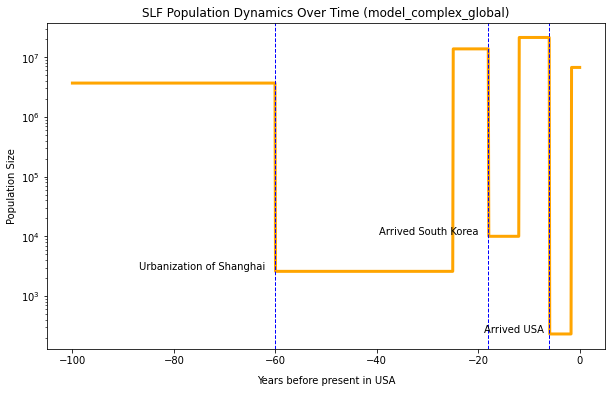

In [91]:
#Try to plot for the best model, 

import matplotlib.pyplot as plt
import numpy as np

# Parameters for the population sizes and time points
n_initial = 3689520
n_shanghai_decline1 = 2587
n_shanghai_expand1 = 13799597
n_korea_decline2 = 10000.00
n_korea_expand2 = 21436465
n_us_decline3 = 231
n_us_expand3 = 6748614
t_initial = 81
t_shanghai_decline1 = 60
t_shanghai_expand1 = 25
t_korea_decline2 = 18
t_korea_expand2 = 12
t_us_decline3 = 6
t_us_expand3 = 1.7

# Time points for the plot
time_points = np.linspace(-100, 0, 1000)  # Covering 100 years to present

# Population size at each time point
population_size = np.zeros_like(time_points)
for i, t in enumerate(time_points):
    if t <= -t_shanghai_decline1:
        population_size[i] = n_initial
    elif -t_shanghai_decline1 < t <= -t_shanghai_expand1:
        population_size[i] = n_shanghai_decline1
    elif -t_shanghai_expand1 < t <= -t_korea_decline2:
        population_size[i] = n_shanghai_expand1
    elif -t_korea_decline2 < t <= -t_korea_expand2:
        population_size[i] = n_korea_decline2
    elif -t_korea_expand2 < t <= -t_us_decline3:
        population_size[i] = n_korea_expand2
    elif -t_us_decline3 < t <= -t_us_expand3:
        population_size[i] = n_us_decline3
    else:
        population_size[i] = n_us_expand3

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(time_points, population_size, color='Orange', linewidth=3)
plt.xlabel('Years before present in USA', labelpad=10)
plt.ylabel('Population Size')
plt.title('SLF Population Dynamics Over Time (model_complex_global)')
plt.grid(False)
plt.yscale('log')  # Log scale for better visualization

# Adding labels for specific events
plt.axvline(x=-t_us_decline3, color='blue', linestyle='--', linewidth=1)
plt.text(-t_us_decline3 -1, n_us_decline3, 'Arrived USA', horizontalalignment='right', verticalalignment='bottom')

plt.axvline(x=-t_korea_decline2, color='blue', linestyle='--', linewidth=1)
plt.text(-t_korea_decline2 - 2 , n_korea_decline2, 'Arrived South Korea', horizontalalignment='right', verticalalignment='bottom')

plt.axvline(x=-t_shanghai_decline1, color='blue', linestyle='--', linewidth=1)
plt.text(-t_shanghai_decline1 - 2, n_shanghai_decline1, 'Urbanization of Shanghai', horizontalalignment='right', verticalalignment='bottom')

# Saving the custom plot as a PDF
plt.savefig("SLF_Complex_Global_Model_Custom_Plot.pdf", format='pdf')

plt.show()



In [127]:
### Model selection with AIC

import numpy as np
AICs = []
model_list = [model_constant,model_expansion,model_decline,model_decline_expand,model_complex_us,model_complex_global]
model_names = ["Constant", "Expansion", "Decline", "Decline and Expand", "Complex US", "Complex Global"]

for model in model_list:
    lik = model.log_likelihood()
    nparams = len(model.get_params())
    aic = 2 * nparams - 2 * lik
    print(f"AIC for {model.__class__.__name__}: {aic}")
    AICs.append(aic)

minv = np.min(AICs)
delta_aic = np.array(AICs) - minv
print("Delta AIC per model: ", delta_aic)
print("AIC weight per model: ", np.exp(-0.5 * delta_aic))

AIC for DemographicModel: 1077901575.4370372
AIC for DemographicModel: 2635934.399345885
AIC for DemographicModel: 2451212.4966737237
AIC for DemographicModel: 2459731.2879741956
AIC for DemographicModel: 2443152.7871946814
AIC for DemographicModel: 2441627.182442166
Delta AIC per model:  [1.07545995e+09 1.94307217e+05 9.58531423e+03 1.81041055e+04
 1.52560475e+03 0.00000000e+00]
AIC weight per model:  [0. 0. 0. 0. 0. 1.]


In [ ]:
### Based on the AIC result, Delta AIC, AIC weight, the the "model_complex_migration_revised_time" has the best fit to the data among the models.
### Its AIC value is the lowest, and its AIC weight is 1, which suggests a very strong likelihood that this model is the best.

In [88]:
# run 1000 replicates for each model and choose the best model

import numpy as np

np.random.seed(318)

model_list = [model_constant, model_expansion, model_decline, model_decline_expand, model_complex_us, model_complex_global]
model_names = ["Constant", "Expansion", "Decline", "Decline and Expand", "Complex US", "Complex Global"]

num_replicates = 1100

with open('318aic_and_likelihoods.txt', 'w') as aic_file, open('318best_models_based_on_weights.txt', 'w') as best_models_file, open('318best_model_params.txt', 'w') as params_file:

    for i in range(num_replicates):
        print(f"Running replicate {i+1} out of {num_replicates}")

        try:
            resampled_sfs = sfs.resample()

            aics = []
            log_likelihoods = []

            for model in model_list:
                model.set_data(resampled_sfs)
                model.set_params(randomize=True)
                model.optimize(method="TNC")
                log_likelihood = model.log_likelihood()
                nparams = len(model.get_params())
                aic = 2 * nparams - 2 * log_likelihood
                aics.append(aic)
                log_likelihoods.append(log_likelihood)

            # Delta AIC calculation
            min_aic = np.min(aics)
            delta_aics = np.array(aics) - min_aic

            # AIC weights calculation
            aic_weights = np.exp(-0.5 * delta_aics) / np.sum(np.exp(-0.5 * delta_aics))

            # Choose the best model based on the highest AIC weight
            best_model_index = np.argmax(aic_weights)
            best_model = model_list[best_model_index]
            params = best_model.get_params()

            # Write detailed info for each replicate to '555aic_and_likelihoods.txt'
            aic_file.write(f'Replicate {i+1}:\n')
            for model_name, aic, ll, delta_aic, aic_weight in zip(model_names, aics, log_likelihoods, delta_aics, aic_weights):
                aic_file.write(f'{model_name} - AIC: {aic}, Log Likelihood: {ll}, Delta AIC: {delta_aic}, AIC Weight: {aic_weight}\n')
            aic_file.write('\n')
            aic_file.flush()

            # Record the index of the best model based on AIC weight for this replicate
            best_models_file.write(f'{best_model_index}\n')
            best_models_file.flush()

            # Save the parameters of the best model for this replicate
            params_file.write(f'Replicate {i+1} Best Model: {model_names[best_model_index]}\n')
            for key, value in params.items():
                params_file.write(f'{key}: {value}\n')
            params_file.write('\n')
            params_file.flush()

        except Exception as e:
            print(f"An error occurred in replicate {i+1}: {str(e)}")
            print("Skipping this replicate and moving on to the next one.")


Running replicate 1 out of 1100


/ext3/miniconda3/envs/momi-py36/lib/python3.6/site-packages/autograd/tracer.py:14: UserWarning: Output seems independent of input.
  warnings.warn("Output seems independent of input.")


Running replicate 2 out of 1100
Running replicate 3 out of 1100
Running replicate 4 out of 1100
Running replicate 5 out of 1100
Running replicate 6 out of 1100
Running replicate 7 out of 1100
Running replicate 8 out of 1100
Running replicate 9 out of 1100
Running replicate 10 out of 1100
Running replicate 11 out of 1100
Running replicate 12 out of 1100
Running replicate 13 out of 1100
Running replicate 14 out of 1100
Running replicate 15 out of 1100
Running replicate 16 out of 1100
Running replicate 17 out of 1100
Running replicate 18 out of 1100
Running replicate 19 out of 1100
Running replicate 20 out of 1100
Running replicate 21 out of 1100
Running replicate 22 out of 1100
Running replicate 23 out of 1100
Running replicate 24 out of 1100
Running replicate 25 out of 1100
Running replicate 26 out of 1100
Running replicate 27 out of 1100
Running replicate 28 out of 1100
Running replicate 29 out of 1100
Running replicate 30 out of 1100
Running replicate 31 out of 1100
Running replicate 

/ext3/miniconda3/envs/momi-py36/lib/python3.6/site-packages/autograd/numpy/numpy_vjps.py:53: RuntimeWarning: overflow encountered in double_scalars
  lambda ans, x, y : unbroadcast_f(y, lambda g: - g * x / y**2))


Running replicate 34 out of 1100
Running replicate 35 out of 1100
Running replicate 36 out of 1100
Running replicate 37 out of 1100
Running replicate 38 out of 1100
Running replicate 39 out of 1100
Running replicate 40 out of 1100
Running replicate 41 out of 1100
Running replicate 42 out of 1100
Running replicate 43 out of 1100
Running replicate 44 out of 1100
Running replicate 45 out of 1100
Running replicate 46 out of 1100
Running replicate 47 out of 1100
Running replicate 48 out of 1100
Running replicate 49 out of 1100
Running replicate 50 out of 1100
Running replicate 51 out of 1100
Running replicate 52 out of 1100
Running replicate 53 out of 1100
Running replicate 54 out of 1100
Running replicate 55 out of 1100
Running replicate 56 out of 1100
Running replicate 57 out of 1100
Running replicate 58 out of 1100
Running replicate 59 out of 1100
Running replicate 60 out of 1100
Running replicate 61 out of 1100
Running replicate 62 out of 1100
Running replicate 63 out of 1100
Running re

/ext3/miniconda3/envs/momi-py36/lib/python3.6/site-packages/autograd/tracer.py:48: RuntimeWarning: overflow encountered in exp
  return f_raw(*args, **kwargs)
/ext3/miniconda3/envs/momi-py36/lib/python3.6/site-packages/autograd/numpy/numpy_vjps.py:75: RuntimeWarning: invalid value encountered in double_scalars
  defvjp(anp.exp,    lambda ans, x : lambda g: ans * g)


An error occurred in replicate 122: Exception encountered at parameter values {'n_initial': 'Autograd ArrayBox with value nan', 'n_shanghai_decline1': 'Autograd ArrayBox with value nan', 'n_shanghai_expand1': 'Autograd ArrayBox with value nan', 'n_korea_decline2': 'Autograd ArrayBox with value nan', 'n_korea_expand2': 'Autograd ArrayBox with value nan', 'n_us_decline3': 'Autograd ArrayBox with value nan', 'n_us_expand3': 'Autograd ArrayBox with value nan', 't_initial': 'Autograd ArrayBox with value nan', 't_shanghai_decline1': 'Autograd ArrayBox with value nan', 't_shanghai_expand1': 'Autograd ArrayBox with value nan', 't_korea_decline2': 'Autograd ArrayBox with value nan', 't_korea_expand2': 'Autograd ArrayBox with value nan', 't_us_decline3': 'Autograd ArrayBox with value nan', 't_us_expand3': 'Autograd ArrayBox with value nan'} (internal scaling x = {'n_initial': 'Autograd ArrayBox with value nan', 'n_shanghai_decline1': 'Autograd ArrayBox with value nan', 'n_shanghai_expand1': 'Aut

In [11]:
model_complex_global.fit_within_pop_diversity() #Estimating mutation rate,To evaluate the total number of mutations in the data, e.g. to fit the mutation rate, use the method DemographicModel.fit_within_pop_diversity, which computes the within-population nucleotide diversity, i.e. the heterozygosity of a random individual in that population assuming Hardy-Weinberg Equilibrium:

,Pop,EstMutRate,JackknifeSD
0,US,6.538848e-10,6.857533e-12


In [9]:
import numpy as np
from momi import SfsModelFitStats

fit_stats = momi.SfsModelFitStats(model_complex_global)

num_samples = sfs.sampled_n[0]  # Number of samples for the "US" population'
print("num_samples",num_samples)

weights = np.linspace(1, 0, num_samples + 1)  # Generate weights for n+1 categories

# Compute the tensor product with the defined weights
tensor_stat = fit_stats.tensor_prod(derived_weights_dict={"US": weights})

# Extract standard deviation and Z-score
print("Standard Deviation:", tensor_stat.sd)
print("Z-Score:", tensor_stat.z_score)


num_samples 196
Standard Deviation: 0.01732579974556093
Z-Score: -0.5127106187943128


In [40]:
#Standard Deviation (SD): This value (0.017) represents the variability or dispersion of the jackknifed values of the tensor product statistic from their mean. A lower standard deviation indicates that the jackknifed values are closer to their mean, suggesting more certainty in the estimate. In demographic inference, this can imply a more consistent pattern across different parts of the genome, thus more confidence in the demographic model's fit to the data.
#A Z-score near zero indicates that the observed data aligns closely with the model's expectations. 

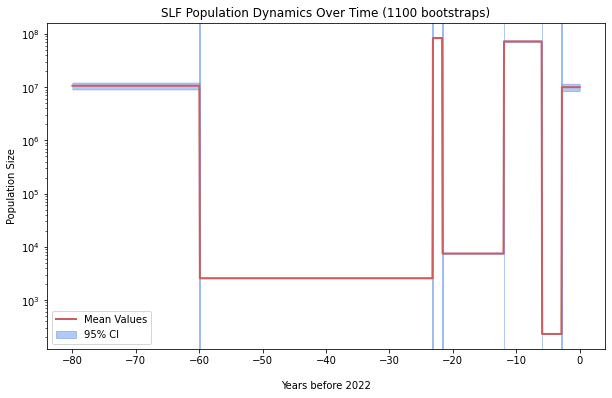

In [7]:
#Plot CI interval for 1100 bootstrap for the best model(three bottlenecks)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Read the statistics data
stats_df = pd.read_csv('stats.momi2.wide.csv')

# Set the 'parameter' column as the index
stats_pivot = stats_df.set_index('parameter')

# Time points for the plot
time_points = np.linspace(-80, 0, 1000)  # Covering 100 years to 2022

# Initialize population size arrays for mean, lower CI, and upper CI
population_size_mean = np.zeros_like(time_points)
population_size_lower = np.zeros_like(time_points)
population_size_upper = np.zeros_like(time_points)

# Define a function to determine the population size at each time point
def get_population_size(t):
    if t <= -stats_pivot.at['t_shanghai_decline1', 'Mean']:
        return ('n_initial',)
    elif -stats_pivot.at['t_shanghai_decline1', 'Mean'] < t <= -stats_pivot.at['t_shanghai_expand1', 'Mean']:
        return ('n_shanghai_decline1',)
    elif -stats_pivot.at['t_shanghai_expand1', 'Mean'] < t <= -stats_pivot.at['t_korea_decline2', 'Mean']:
        return ('n_shanghai_expand1',)
    elif -stats_pivot.at['t_korea_decline2', 'Mean'] < t <= -stats_pivot.at['t_korea_expand2', 'Mean']:
        return ('n_korea_decline2',)
    elif -stats_pivot.at['t_korea_expand2', 'Mean'] < t <= -stats_pivot.at['t_us_decline3', 'Mean']:
        return ('n_korea_expand2',)
    elif -stats_pivot.at['t_us_decline3', 'Mean'] < t <= -stats_pivot.at['t_us_expand3', 'Mean']:
        return ('n_us_decline3',)
    else:
        return ('n_us_expand3',)

# Calculate the mean, lower CI, and upper CI for each time point
for i, t in enumerate(time_points):
    param = get_population_size(t)
    population_size_lower[i] = stats_pivot.at[param[0], '95% CI Lower']
    population_size_upper[i] = stats_pivot.at[param[0], '95% CI Upper']
    population_size_mean[i] = stats_pivot.at[param[0], 'Mean']

# Plotting
plt.figure(figsize=(10, 6))
#plt.plot(time_points, population_size_mean, color='indianred', linewidth=2, label='Mean Values')
plt.fill_between(time_points, population_size_lower, population_size_upper, color='cornflowerblue', alpha=0.5, label='95% CI')
plt.plot(time_points, population_size_mean, color='indianred', linewidth=2, label='Mean Values')
plt.legend(loc='lower left')

# Plot CI for time parameters (excluding the initial time point)
for param in ['t_shanghai_decline1', 't_shanghai_expand1', 't_korea_decline2', 't_korea_expand2', 't_us_decline3', 't_us_expand3']:
    mean = -stats_pivot.at[param, 'Mean']
    lower = -stats_pivot.at[param, '95% CI Lower']
    upper = -stats_pivot.at[param, '95% CI Upper']
    plt.axvspan(lower, upper, alpha=0.5, color='cornflowerblue')

plt.xlabel('Years before 2022', labelpad=15)
plt.ylabel('Population Size')
plt.title('SLF Population Dynamics Over Time (1100 bootstraps)')
plt.grid(False)
plt.yscale('log')  # Log scale for better visualization

plt.legend(loc='lower left')

# Saving the custom plot as a PDF
plt.savefig("SLF_Final_Three_Bottlenecks_CI_Plot.png", format='png')
plt.show()

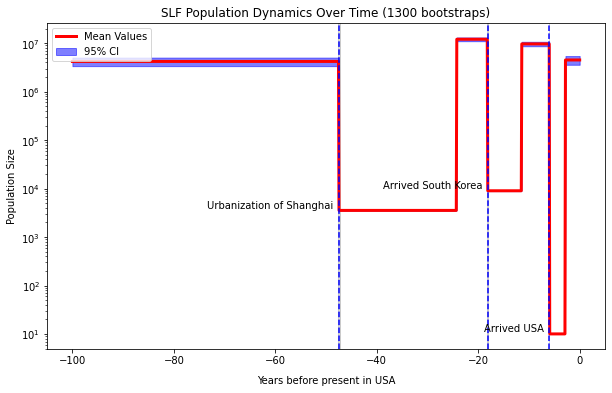

In [58]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Read the statistics data
stats_df = pd.read_csv('stats.momi2.txt')

# Convert the DataFrame into a pivot table with parameters as index, statistics as columns
stats_pivot = stats_df.pivot(index='parameter', columns='statistic', values='value')

# Time points for the plot
time_points = np.linspace(-100, 0, 1000)  # Covering 100 years to present

# Initialize population size arrays for mean, lower CI, and upper CI
population_size_mean = np.zeros_like(time_points)
population_size_lower = np.zeros_like(time_points)
population_size_upper = np.zeros_like(time_points)

# Define a function to determine the population size at each time point
def get_population_size(t):
    if t <= -stats_pivot.at['t_shanghai_decline1', 'mean']:
        return ('n_initial',)
    elif -stats_pivot.at['t_shanghai_decline1', 'mean'] < t <= -stats_pivot.at['t_shanghai_expand1', 'mean']:
        return ('n_shanghai_decline1',)
    elif -stats_pivot.at['t_shanghai_expand1', 'mean'] < t <= -stats_pivot.at['t_korea_decline2', 'mean']:
        return ('n_shanghai_expand1',)
    elif -stats_pivot.at['t_korea_decline2', 'mean'] < t <= -stats_pivot.at['t_korea_expand2', 'mean']:
        return ('n_korea_decline2',)
    elif -stats_pivot.at['t_korea_expand2', 'mean'] < t <= -stats_pivot.at['t_us_decline3', 'mean']:
        return ('n_korea_expand2',)
    elif -stats_pivot.at['t_us_decline3', 'mean'] < t <= -stats_pivot.at['t_us_expand3', 'mean']:
        return ('n_us_decline3',)
    else:
        return ('n_us_expand3',)

# Calculate the mean, lower CI, and upper CI for each time point
for i, t in enumerate(time_points):
    param = get_population_size(t)
    population_size_mean[i] = stats_pivot.at[param[0], 'mean']
    population_size_lower[i] = stats_pivot.at[param[0], 'lower']
    population_size_upper[i] = stats_pivot.at[param[0], 'upper']

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(time_points, population_size_mean, color='red', linewidth=3, label='Mean Values')
plt.fill_between(time_points, population_size_lower, population_size_upper, color='blue', alpha=0.5, label='95% CI')
plt.xlabel('Years before present in USA', labelpad=10)
plt.ylabel('Population Size')
plt.title('SLF Population Dynamics Over Time (1300 bootstraps)')
plt.grid(False)
plt.yscale('log')  # Log scale for better visualization

# Add the vertical lines and text annotations for specified events
params = ['t_us_decline3', 't_korea_decline2', 't_shanghai_decline1']
labels = ['Arrived USA', 'Arrived South Korea', 'Urbanization of Shanghai']
n_params = ['n_us_decline3', 'n_korea_decline2', 'n_shanghai_decline1']

for param, label, n_param in zip(params, labels, n_params):
    mean = -stats_pivot.at[param, 'mean']
    pop_mean = stats_pivot.at[n_param, 'mean']
    plt.axvline(x=mean, color='lightgreen', linestyle='--', linewidth=1)
    plt.text(mean, pop_mean, label, horizontalalignment='left', verticalalignment='bottom')

# Saving the custom plot as a PDF
plt.savefig("SLF_Complex_Global_Model_CI_Plot.pdf", format='pdf')
plt.show()

In [9]:
# Narrow range of 95% CI for each decline
# Check the values for 'n_us_decline3' and 'n_shanghai_decline1'
params_to_check = ['n_us_decline3', 'n_shanghai_decline1']

for param in params_to_check:
    mean = stats_pivot.at[param, 'Mean']
    lower = stats_pivot.at[param, '95% CI Lower']
    upper = stats_pivot.at[param, '95% CI Upper']
    
    print(f"Parameter: {param}")
    print(f"Mean: {mean}")
    print(f"95% CI Lower: {lower}")
    print(f"95% CI Upper: {upper}")
    
    diff_lower = mean - lower
    diff_upper = upper - mean
    
    print(f"Difference between Mean and 95% CI Lower: {diff_lower}")
    print(f"Difference between 95% CI Upper and Mean: {diff_upper}")
    
    ratio_lower = diff_lower / mean
    ratio_upper = diff_upper / mean
    
    print(f"Ratio of difference (Mean - 95% CI Lower) to Mean: {ratio_lower}")
    print(f"Ratio of difference (95% CI Upper - Mean) to Mean: {ratio_upper}")
    print("---")

Parameter: n_us_decline3
Mean: 230.78957509925
95% CI Lower: 230.475308375367
95% CI Upper: 231.10384182313302
Difference between Mean and 95% CI Lower: 0.31426672388298016
Difference between 95% CI Upper and Mean: 0.314266723883037
Ratio of difference (Mean - 95% CI Lower) to Mean: 0.0013617024241577254
Ratio of difference (95% CI Upper - Mean) to Mean: 0.0013617024241579718
---
Parameter: n_shanghai_decline1
Mean: 2573.9014341933603
95% CI Lower: 2572.2828080067898
95% CI Upper: 2575.5200603799303
Difference between Mean and 95% CI Lower: 1.6186261865705092
Difference between 95% CI Upper and Mean: 1.6186261865700544
Ratio of difference (Mean - 95% CI Lower) to Mean: 0.0006288609832014695
Ratio of difference (95% CI Upper - Mean) to Mean: 0.0006288609832012929
---


In [22]:
#plot tables for stats
import pandas as pd
import matplotlib.pyplot as plt

# List of CSV files
#csv_files = ['model_results.csv', 'Parameters.momi2.wide.csv', 'stats.momi2.wide.csv']
csv_files = ['Parameters.momi2.wide.csv']

for csv_file in csv_files:
    # Read the CSV file into a DataFrame
    df = pd.read_csv(csv_file)

    # Replace 'nan' with an empty string in the DataFrame
    df = df.fillna('')

    # Create a new figure and axis with a wider size
    fig, ax = plt.subplots(figsize=(20, 8))

    # Hide axes
    fig.patch.set_visible(False)
    ax.axis('off')
    ax.axis('tight')

    # Create the table
    table = ax.table(cellText=df.values, colLabels=df.columns, loc='center', cellLoc='center')

    # Set the font size and scale the table
    table.auto_set_font_size(False)
    table.set_fontsize(10)  # Adjust the font size as needed

    # Adjust cell padding
    cell_dict = table.get_celld()
    for i in range(len(df.columns)):
        cell_dict[(0, i)].set_height(0.1)
        for j in range(len(df)):
            cell_dict[(j + 1, i)].set_height(0.1)

    # Adjust layout and save the figure as PDF
    fig.tight_layout()
    plt.savefig(f"{csv_file.split('.')[0]}_table.pdf", format='pdf', bbox_inches='tight')

    # Close the figure to free up memory
    plt.close(fig)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the CSV file into a DataFrame
df = pd.read_csv('Parameters.momi2.wide.csv')

# Replace 'nan' with an empty string in the DataFrame
df = df.fillna('')

# Create a new figure and axis with a wider size
fig, ax = plt.subplots(figsize=(20, 8))  # Increase the width to 30 inches

# Hide axes
fig.patch.set_visible(False)
ax.axis('off')
ax.axis('tight')

# Create the table
table = ax.table(cellText=df.values, colLabels=df.columns, loc='center', cellLoc='center')

# Set the font size and scale the table
table.auto_set_font_size(False)
table.set_fontsize(14)  # Adjust the font size to fit the wider table

# Adjust cell padding
cell_dict = table.get_celld()
for i in range(len(df.columns)):
    cell_dict[(0, i)].set_height(0.1)
    for j in range(len(df)):
        cell_dict[(j + 1, i)].set_height(0.1)

# Adjust layout and save the figure as PDF
fig.tight_layout()
plt.savefig('Parameters.momi2.wide_table.pdf', format='pdf', bbox_inches='tight')

# Display the table
plt.show()